# Official 2025 NYC Citi Bike EDA

真实已完成骑行档案；模拟服务指标基于假设，非真实历史缺车。未确认运营的小时在审计 panel 中保持未知；正式模型使用单独标注的 archived event counts 口径，零记录不等于零潜在需求。

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
assert (ROOT/'src').exists(), 'Run from repository root'
data=ROOT/'data/processed'
out=ROOT/'outputs/official'
panel=pd.read_parquet(data/'panel.parquet')
print('OFFICIAL 2025 ARCHIVE COUNTS', panel.shape)
display(pd.read_csv(data/'data_quality_summary.csv'))

OFFICIAL 2025 ARCHIVE COUNTS (262800, 9)


,data_kind,months,complete_year,raw_rows,retained_rides,stations,panel_rows,unknown_hours,count_conservation,dst_policy,zero_policy
0,official,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]",True,45771102,45588101,30,262800,19634,passed,exclude unresolvable local folds/gaps; retain ...,unobserved hours missing unless operating cale...


,hour,departures,arrivals,total
0,2025-09-11 00:00:00+00:00,16196.0,16211.0,32407.0
1,2025-09-30 00:00:00+00:00,16117.0,16020.0,32137.0
2,2025-09-26 00:00:00+00:00,15803.0,15652.0,31455.0
3,2025-09-18 00:00:00+00:00,15751.0,15533.0,31284.0
4,2025-09-19 00:00:00+00:00,15720.0,15543.0,31263.0


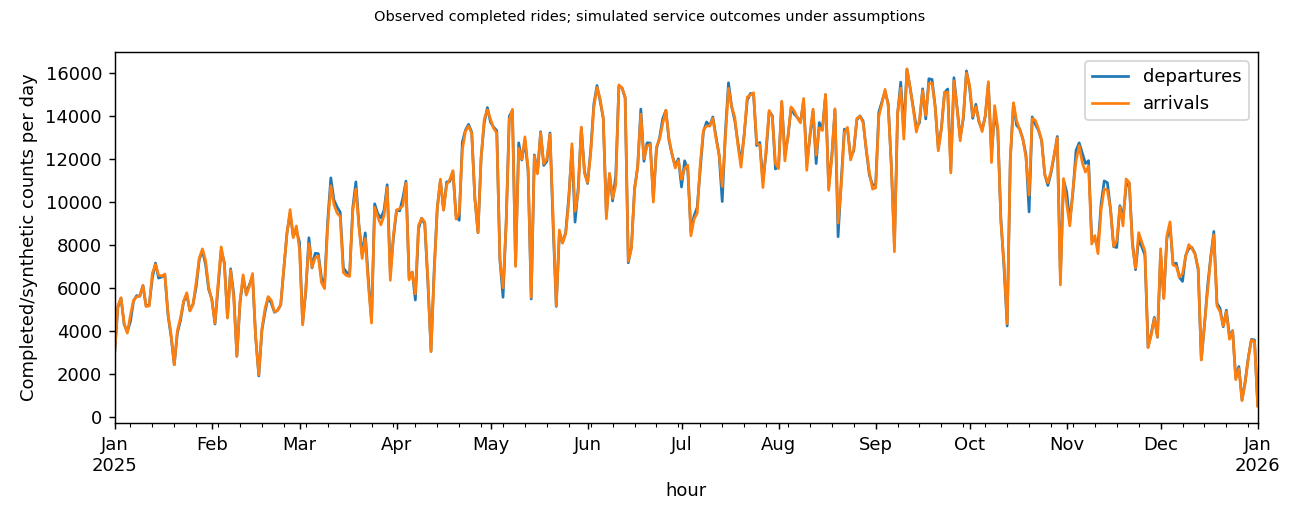

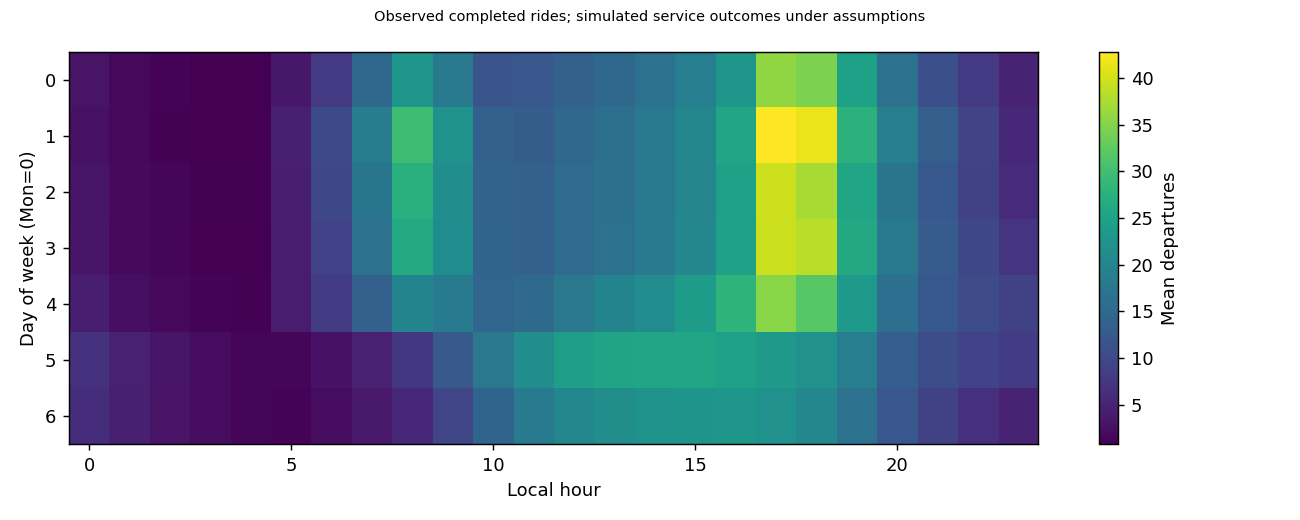

In [2]:
display(pd.read_csv(out/'anomalous_dates.csv').head())
display(Image(filename=str(out/'figures/eda_daily.png')))
display(Image(filename=str(out/'figures/eda_heatmap.png')))

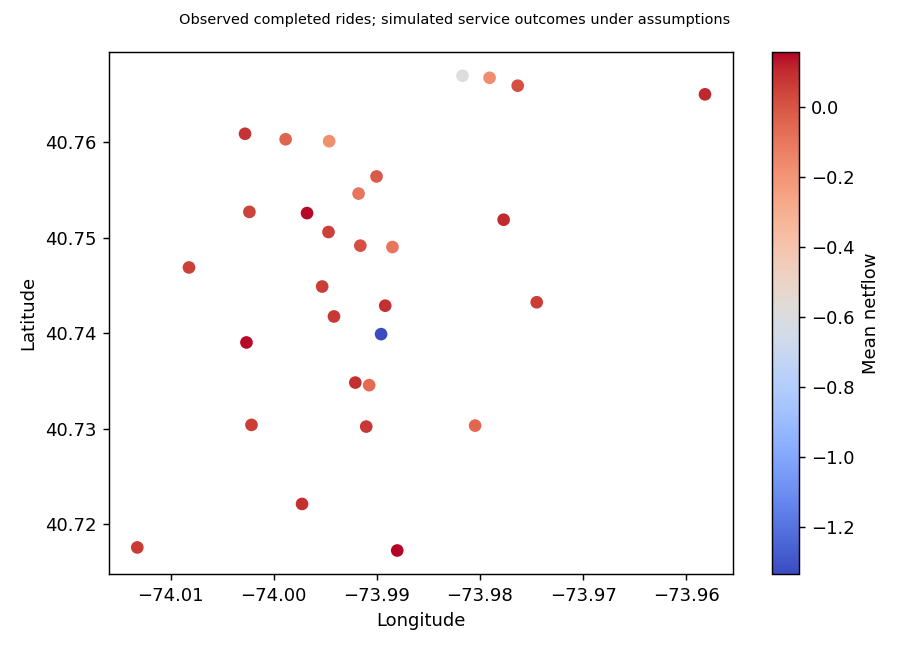

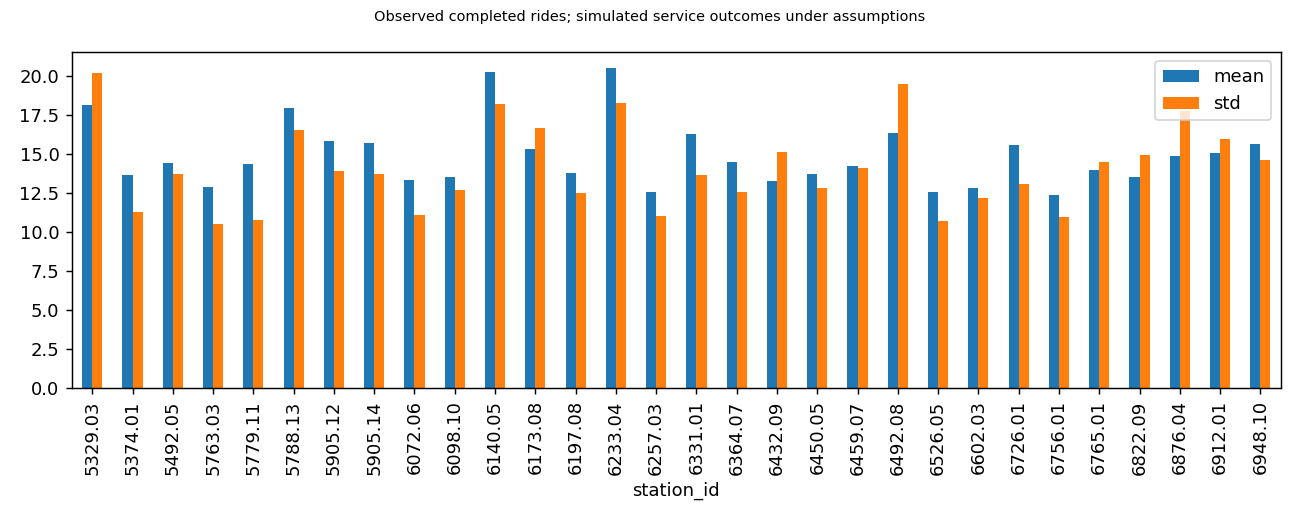

,station_id,mean,std,min,median,max
0,5329.03,0.068014,8.592162,-65.0,0.0,58.0
1,5374.01,0.157143,6.020429,-37.0,0.0,43.0
2,5492.05,0.091335,5.098201,-27.0,0.0,27.0
3,5763.03,0.061362,6.111347,-28.0,0.0,32.0
4,5779.11,-0.050605,5.028901,-24.0,0.0,29.0


In [3]:
display(Image(filename=str(out/'figures/eda_map.png')))
display(Image(filename=str(out/'figures/eda_heterogeneity.png')))
display(pd.read_csv(out/'station_netflow_distribution.csv').head())

,model,target,split,stratum,n,mae,rmse,wape
2,last_hour,departures,test,all,43950,4.475768,7.134479,0.451975
5,seasonal_naive,departures,test,all,43950,5.718726,9.154236,0.577492
8,poisson,departures,test,all,43950,4.931489,6.652226,0.497995
11,xgboost,departures,test,all,43950,3.417684,5.056675,0.345127
14,last_hour,arrivals,test,all,43950,4.409101,7.200692,0.448702
17,seasonal_naive,arrivals,test,all,43950,5.721706,9.242284,0.582282
20,poisson,arrivals,test,all,43950,4.838438,6.638734,0.492394
23,xgboost,arrivals,test,all,43950,3.398162,5.111224,0.345821


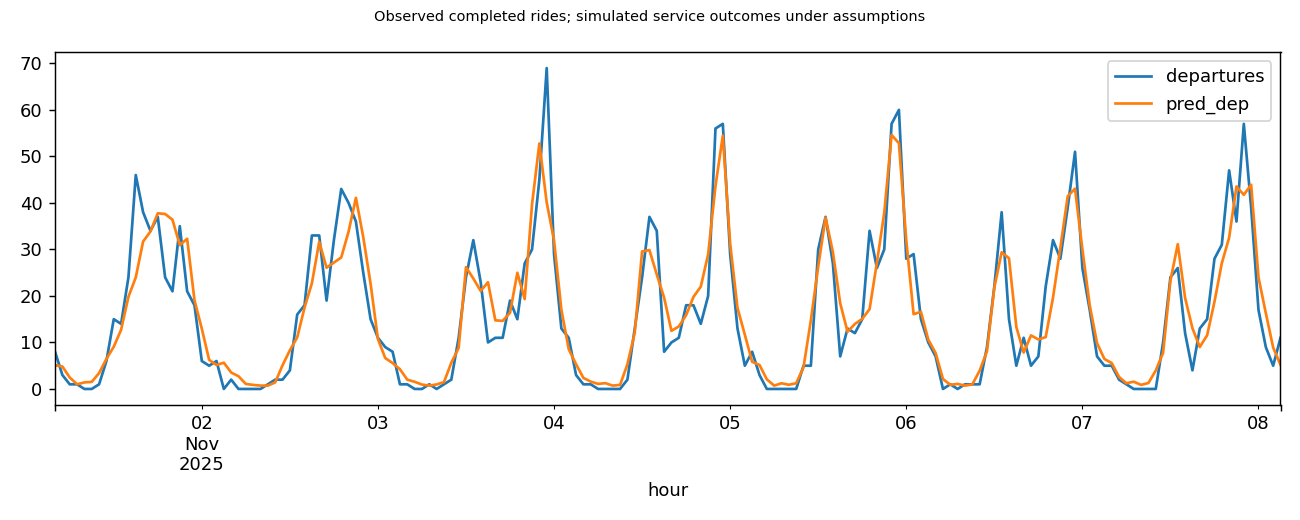

In [4]:
metrics=pd.read_csv(out/'forecast_metrics.csv')
display(metrics[(metrics.split=='test') & (metrics.stratum=='all')])
display(Image(filename=str(out/'figures/forecast_trace.png')))

In [5]:
display(pd.read_csv(out/'simulation_summary.csv'))
display(pd.read_csv(out/'uncertainty_summary.csv'))
print('Hourly count-based scenario simulation; no historical service claim.')

,strategy,departure_requests,arrival_events,unmet_departures,blocked_arrivals,bikes_moved,bike_km,scenario_objective,proxy_service_rate,mean_runtime_ms,fallback_hours,data_kind,simulation_kind,hours
0,none,435223,431868,42028,38689,0,0.000000,403585.000000,0.903433,0.412349,0,official,hourly count-based scenario simulation,1465
1,greedy,435223,431868,39510,36167,17259,8590.202820,379244.020282,0.909219,0.506382,0,official,hourly count-based scenario simulation,1465
2,milp,435223,431868,35982,32639,16442,15846.879083,344689.687908,0.917325,7.881864,0,official,hourly count-based scenario simulation,1465


,strategy,baseline,metric,days,ci_low,ci_high,method
0,greedy,none,daily_scenario_objective_difference,61,-459.522661,-344.384389,paired local-day block bootstrap; scenario unc...
1,milp,none,daily_scenario_objective_difference,61,-1029.915137,-901.728249,paired local-day block bootstrap; scenario unc...
2,milp,greedy,daily_scenario_objective_difference,61,-610.922799,-521.427542,paired local-day block bootstrap; scenario unc...


Hourly count-based scenario simulation; no historical service claim.


## 解释边界

小时与周模式为描述性关联；不能由高峰或极值直接推断天气、停运等原因。运营未知小时未被宣称为确认营业。容量、初始库存、调运时间和受阻归还行为均是假设，参见 final_report.md 与字典。